# Project 04: First Machine Learning Classifier

## 1. Define the prediction
**Predict whether a passenger survived the Titanic from their class, sex, age and fare.**

- **Target:** `survived` (1 = survived, 0 = did not)
- **Features:** `pclass`, `sex`, `age`, `fare`

The model is a **Decision Tree**, compared against a simple **baseline** (always guessing the most common outcome).

## 2. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid", palette="colorblind")

raw = sns.load_dataset("titanic")
FEATURES = ["pclass", "sex", "age", "fare"]        # keep this order everywhere, including the app
df = raw[["survived"] + FEATURES].copy()

print("Rows before:", len(df), "| missing values:", df.isna().sum().to_dict())
df = df.dropna()
df["sex"] = (df["sex"] == "female").astype(int)    # female = 1, male = 0
print("Rows after dropping missing values:", len(df))

X, y = df[FEATURES], df["survived"]
df.head()

Rows before: 891 | missing values: {'survived': 0, 'pclass': 0, 'sex': 0, 'age': 177, 'fare': 0}
Rows after dropping missing values: 714


,survived,pclass,sex,age,fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


I **drop** the rows with a missing `age` (about 20%). Filling them would mean inventing ages for the very feature I want the model to learn from. The cost is a smaller dataset, which I mention in the limitations.

## 3. Split the data
`test_size=0.2` keeps 20% of passengers hidden for testing, `random_state=42` makes the result repeatable, and `stratify=y` gives both sets a similar survival rate.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Survival rate  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")

Train: (571, 4) | Test: (143, 4)
Survival rate  train: 0.406  test: 0.406


## 4. Set a baseline
The baseline always guesses the most common outcome. **My model must beat this to be useful.**

In [3]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print(f"Baseline accuracy (always guess '{int(y_test.mean() < 0.5)}'): {baseline:.3f}")

Baseline accuracy (always guess '1'): 0.594


## 5. Train a model (on the training data only)

In [4]:
model = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)
print(model)

DecisionTreeClassifier(max_depth=4, random_state=42)


## 6. Evaluate on the test set

Baseline accuracy: 0.594
Model accuracy:    0.797

Confusion matrix (rows = actual, columns = predicted):
[[72 13]
 [16 42]]


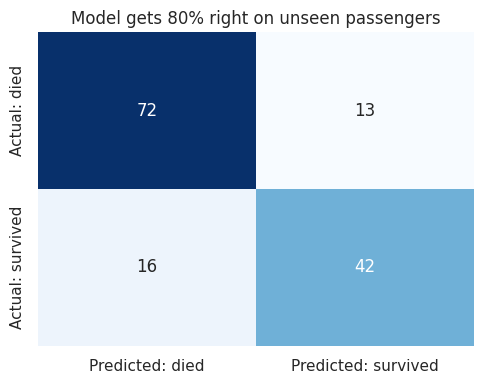

              precision    recall  f1-score   support

        died       0.82      0.85      0.83        85
    survived       0.76      0.72      0.74        58

    accuracy                           0.80       143
   macro avg       0.79      0.79      0.79       143
weighted avg       0.80      0.80      0.80       143



In [5]:
pred = model.predict(X_test)
acc = accuracy_score(y_test, pred)
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()

print(f"Baseline accuracy: {baseline:.3f}")
print(f"Model accuracy:    {acc:.3f}")
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Predicted: died", "Predicted: survived"],
            yticklabels=["Actual: died", "Actual: survived"])
ax.set_title(f"Model gets {acc:.0%} right on unseen passengers")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_test, pred, target_names=["died", "survived"]))

In [6]:
display(Markdown(f"""
### What each cell of the confusion matrix means (test set of {len(y_test)} passengers)
| | Predicted: died | Predicted: survived |
|---|---|---|
| **Actually died** | **{tn}** true negatives: correctly predicted death | **{fp}** false positives: predicted survival, but they died |
| **Actually survived** | **{fn}** false negatives: predicted death, but they survived | **{tp}** true positives: correctly predicted survival |

The model is right for **{tn + tp} of {len(y_test)}** passengers (**{acc:.1%}**), versus **{baseline:.1%}** for the baseline. **Accuracy alone can mislead:** the matrix shows it finds {tp} of the {tp + fn} real survivors (recall {tp / (tp + fn):.0%}). It wrongly predicts death for {fn} survivors and wrongly predicts survival for {fp} people who died, so the two kinds of error are {'similar in size' if abs(fn - fp) <= 3 else 'not equally common'}.
"""))


### What each cell of the confusion matrix means (test set of 143 passengers)
| | Predicted: died | Predicted: survived |
|---|---|---|
| **Actually died** | **72** true negatives: correctly predicted death | **13** false positives: predicted survival, but they died |
| **Actually survived** | **16** false negatives: predicted death, but they survived | **42** true positives: correctly predicted survival |

The model is right for **114 of 143** passengers (**79.7%**), versus **59.4%** for the baseline. **Accuracy alone can mislead:** the matrix shows it finds 42 of the 58 real survivors (recall 72%). It wrongly predicts death for 16 survivors and wrongly predicts survival for 13 people who died, so the two kinds of error are similar in size.


## 7. Test depth and overfitting
I try `max_depth` from 1 to 12 and compare accuracy on the training data and on the test data.

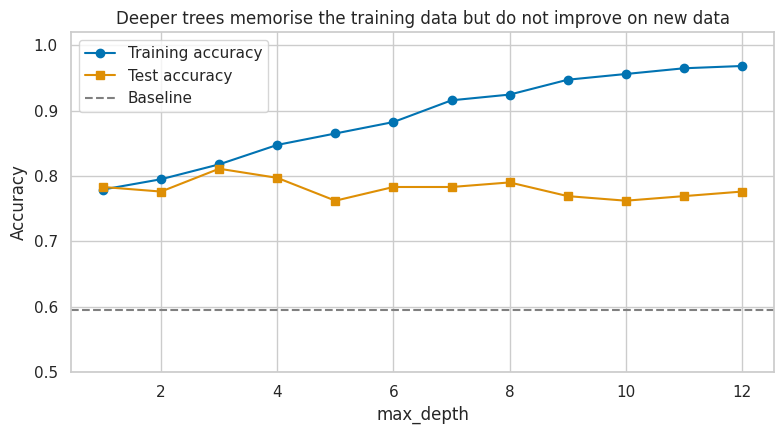

,train_acc,test_acc
max_depth,,
1,0.779,0.783
2,0.795,0.776
3,0.818,0.811
4,0.848,0.797
5,0.865,0.762
6,0.883,0.783
7,0.916,0.783
8,0.925,0.790
9,0.947,0.769


In [7]:
rows = []
for d in range(1, 13):
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": d,
                 "train_acc": accuracy_score(y_train, m.predict(X_train)),
                 "test_acc": accuracy_score(y_test, m.predict(X_test))})
depth = pd.DataFrame(rows).set_index("max_depth")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(depth.index, depth["train_acc"], marker="o", label="Training accuracy")
ax.plot(depth.index, depth["test_acc"], marker="s", label="Test accuracy")
ax.axhline(baseline, ls="--", color="grey", label="Baseline")
ax.set(title="Deeper trees memorise the training data but do not improve on new data",
       xlabel="max_depth", ylabel="Accuracy", ylim=(0.5, 1.02))
ax.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png", dpi=150)
plt.show()
depth.round(3)

In [8]:
best_d = int(depth["test_acc"].idxmax())
display(Markdown(f"""
At depth 12 the tree scores **{depth.loc[12, 'train_acc']:.0%}** on the training data but only **{depth.loc[12, 'test_acc']:.0%}** on the test data. A very deep tree has enough splits to **memorise** individual training passengers, including their noise, so it does worse on passengers it has not seen. That is **overfitting**. A very shallow tree (depth 1) is too simple (underfitting).

I keep **max_depth=4**, a shallow tree with a small gap between training ({depth.loc[4, 'train_acc']:.0%}) and test ({depth.loc[4, 'test_acc']:.0%}) accuracy. Test accuracy is highest at depth {best_d} in this single split, but picking a depth by looking at the test set would make the test score optimistic, and the differences between nearby depths are small and noisy.
"""))


At depth 12 the tree scores **97%** on the training data but only **78%** on the test data. A very deep tree has enough splits to **memorise** individual training passengers, including their noise, so it does worse on passengers it has not seen. That is **overfitting**. A very shallow tree (depth 1) is too simple (underfitting).

I keep **max_depth=4**, a shallow tree with a small gap between training (85%) and test (80%) accuracy. Test accuracy is highest at depth 3 in this single split, but picking a depth by looking at the test set would make the test score optimistic, and the differences between nearby depths are small and noisy.


## 8. What I learned

{'sex': 0.55, 'pclass': 0.24, 'age': 0.14, 'fare': 0.08}


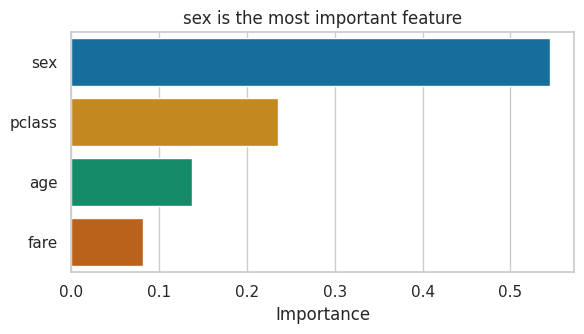

In [9]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values(ascending=False)
print(imp.round(2).to_dict())

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, legend=False, ax=ax)
ax.set(title=f"{imp.index[0]} is the most important feature", xlabel="Importance", ylabel="")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

In [10]:
display(Markdown(f"""
### Summary
- **Accuracy:** the decision tree scores **{acc:.1%}** on unseen passengers, compared with a baseline of **{baseline:.1%}**, so it beats guessing by about **{(acc - baseline) * 100:.1f} percentage points**.
- **Most important features:** **{imp.index[0]}** ({imp.iloc[0]:.0%}) and **{imp.index[1]}** ({imp.iloc[1]:.0%}) drive most of the decisions.
- **Overfitting:** accuracy on training data keeps rising with depth while test accuracy stops improving.

### Limitations
- **Small dataset:** only {len(df)} passengers remain after dropping rows with no age, and a 20% test set is about {len(y_test)} people, so the accuracy figure is **noisy**. A different random split could change it by several points.
- **Dropped rows:** removing passengers with missing age may bias the data if those passengers differ from the rest.
- **Few features:** the model ignores family size, title and cabin, which could add information.
- **Historical data:** it describes one event and does not generalise to other situations.
"""))


### Summary
- **Accuracy:** the decision tree scores **79.7%** on unseen passengers, compared with a baseline of **59.4%**, so it beats guessing by about **20.3 percentage points**.
- **Most important features:** **sex** (55%) and **pclass** (24%) drive most of the decisions.
- **Overfitting:** accuracy on training data keeps rising with depth while test accuracy stops improving.

### Limitations
- **Small dataset:** only 714 passengers remain after dropping rows with no age, and a 20% test set is about 143 people, so the accuracy figure is **noisy**. A different random split could change it by several points.
- **Dropped rows:** removing passengers with missing age may bias the data if those passengers differ from the rest.
- **Few features:** the model ignores family size, title and cabin, which could add information.
- **Historical data:** it describes one event and does not generalise to other situations.


## 9. Save the model for the web app (Project 05)

In [11]:
joblib.dump(model, "model.joblib")
print("Saved model.joblib | feature order:", FEATURES)

app_dir = Path("../project05")
if app_dir.exists():
    joblib.dump(model, app_dir / "model.joblib")
    print("Also copied to", app_dir / "model.joblib")

Saved model.joblib | feature order: ['pclass', 'sex', 'age', 'fare']
Also copied to ../project05/model.joblib
